# Trực quan hóa không gian véc-tơ Word Embedding tiếng Việt
### Mô hình Skip-gram & CBOW (PyTorch From-scratch)

Notebook này thực hiện:
1. Nạp ma trận embedding đã huấn luyện từ `models/skipgram.pt` và `models/cbow.pt`.
2. Trích xuất véc-tơ cho **10 cặp từ** mang ý nghĩa ngữ nghĩa đa dạng.
3. Giảm chiều dữ liệu xuống **2D** và **3D** bằng thuật toán **PCA**.
4. Trực quan hóa và so sánh cấu trúc hình học ngữ nghĩa giữa hai mô hình.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import torch

# Thiết lập font và style vẽ
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Liberation Sans']
plt.rcParams['axes.unicode_minus'] = False
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

## 1. Định nghĩa 10 cặp từ và nạp mô hình

In [2]:
WORD_PAIRS = [
    ("hà_nội", "việt_nam", "Thủ đô - Quốc gia"),
    ("tokyo", "nhật_bản", "Thủ đô - Quốc gia"),
    ("paris", "pháp", "Thủ đô - Quốc gia"),
    ("vua", "hoàng_hậu", "Hoàng gia / Giới tính"),
    ("đàn_ông", "phụ_nữ", "Giới tính"),
    ("cha", "mẹ", "Gia đình"),
    ("học_sinh", "giáo_viên", "Giáo dục"),
    ("bác_sĩ", "bệnh_viện", "Y tế"),
    ("thành_phố", "nông_thôn", "Địa lý"),
    ("thành_công", "thất_bại", "Trái nghĩa")
]

def load_embeddings(model_path):
    if not os.path.exists(model_path):
        alt_paths = [
            os.path.join("models", os.path.basename(model_path)),
            os.path.join("..", "models", os.path.basename(model_path))
        ]
        for alt in alt_paths:
            if os.path.exists(alt):
                model_path = alt
                break
    chk = torch.load(model_path, map_location="cpu", weights_only=False)
    embeds = chk["embeddings"]
    if isinstance(embeds, torch.Tensor):
        embeds = embeds.numpy()
    return embeds, chk["word2idx"], chk["idx2word"]

sg_embeds, sg_w2i, sg_i2w = load_embeddings("models/skipgram.pt")
cbow_embeds, cbow_w2i, cbow_i2w = load_embeddings("models/cbow.pt")

print(f"Skip-gram vocab size: {len(sg_w2i)}, embedding dim: {sg_embeds.shape[1]}")
print(f"CBOW vocab size: {len(cbow_w2i)}, embedding dim: {cbow_embeds.shape[1]}")


Skip-gram vocab size: 14964, embedding dim: 100
CBOW vocab size: 14964, embedding dim: 100


## 2. Trích xuất véc-tơ của 10 cặp từ (20 từ)

In [3]:
unique_words = []
for w1, w2, _ in WORD_PAIRS:
    if w1 not in unique_words and w1 in sg_w2i:
        unique_words.append(w1)
    if w2 not in unique_words and w2 in sg_w2i:
        unique_words.append(w2)

sg_vectors = np.array([sg_embeds[sg_w2i[w]] for w in unique_words])
cbow_vectors = np.array([cbow_embeds[cbow_w2i[w]] for w in unique_words])

print(f"Tổng số từ trích xuất: {len(unique_words)}")
print("Danh sách các từ:", unique_words)

Tổng số từ trích xuất: 20
Danh sách các từ: ['hà_nội', 'việt_nam', 'tokyo', 'nhật_bản', 'paris', 'pháp', 'vua', 'hoàng_hậu', 'đàn_ông', 'phụ_nữ', 'cha', 'mẹ', 'học_sinh', 'giáo_viên', 'bác_sĩ', 'bệnh_viện', 'thành_phố', 'nông_thôn', 'thành_công', 'thất_bại']


## 3. Trực quan hóa 2D (PCA)


Đã lưu ảnh biểu đồ vào: results/pca_2d.png


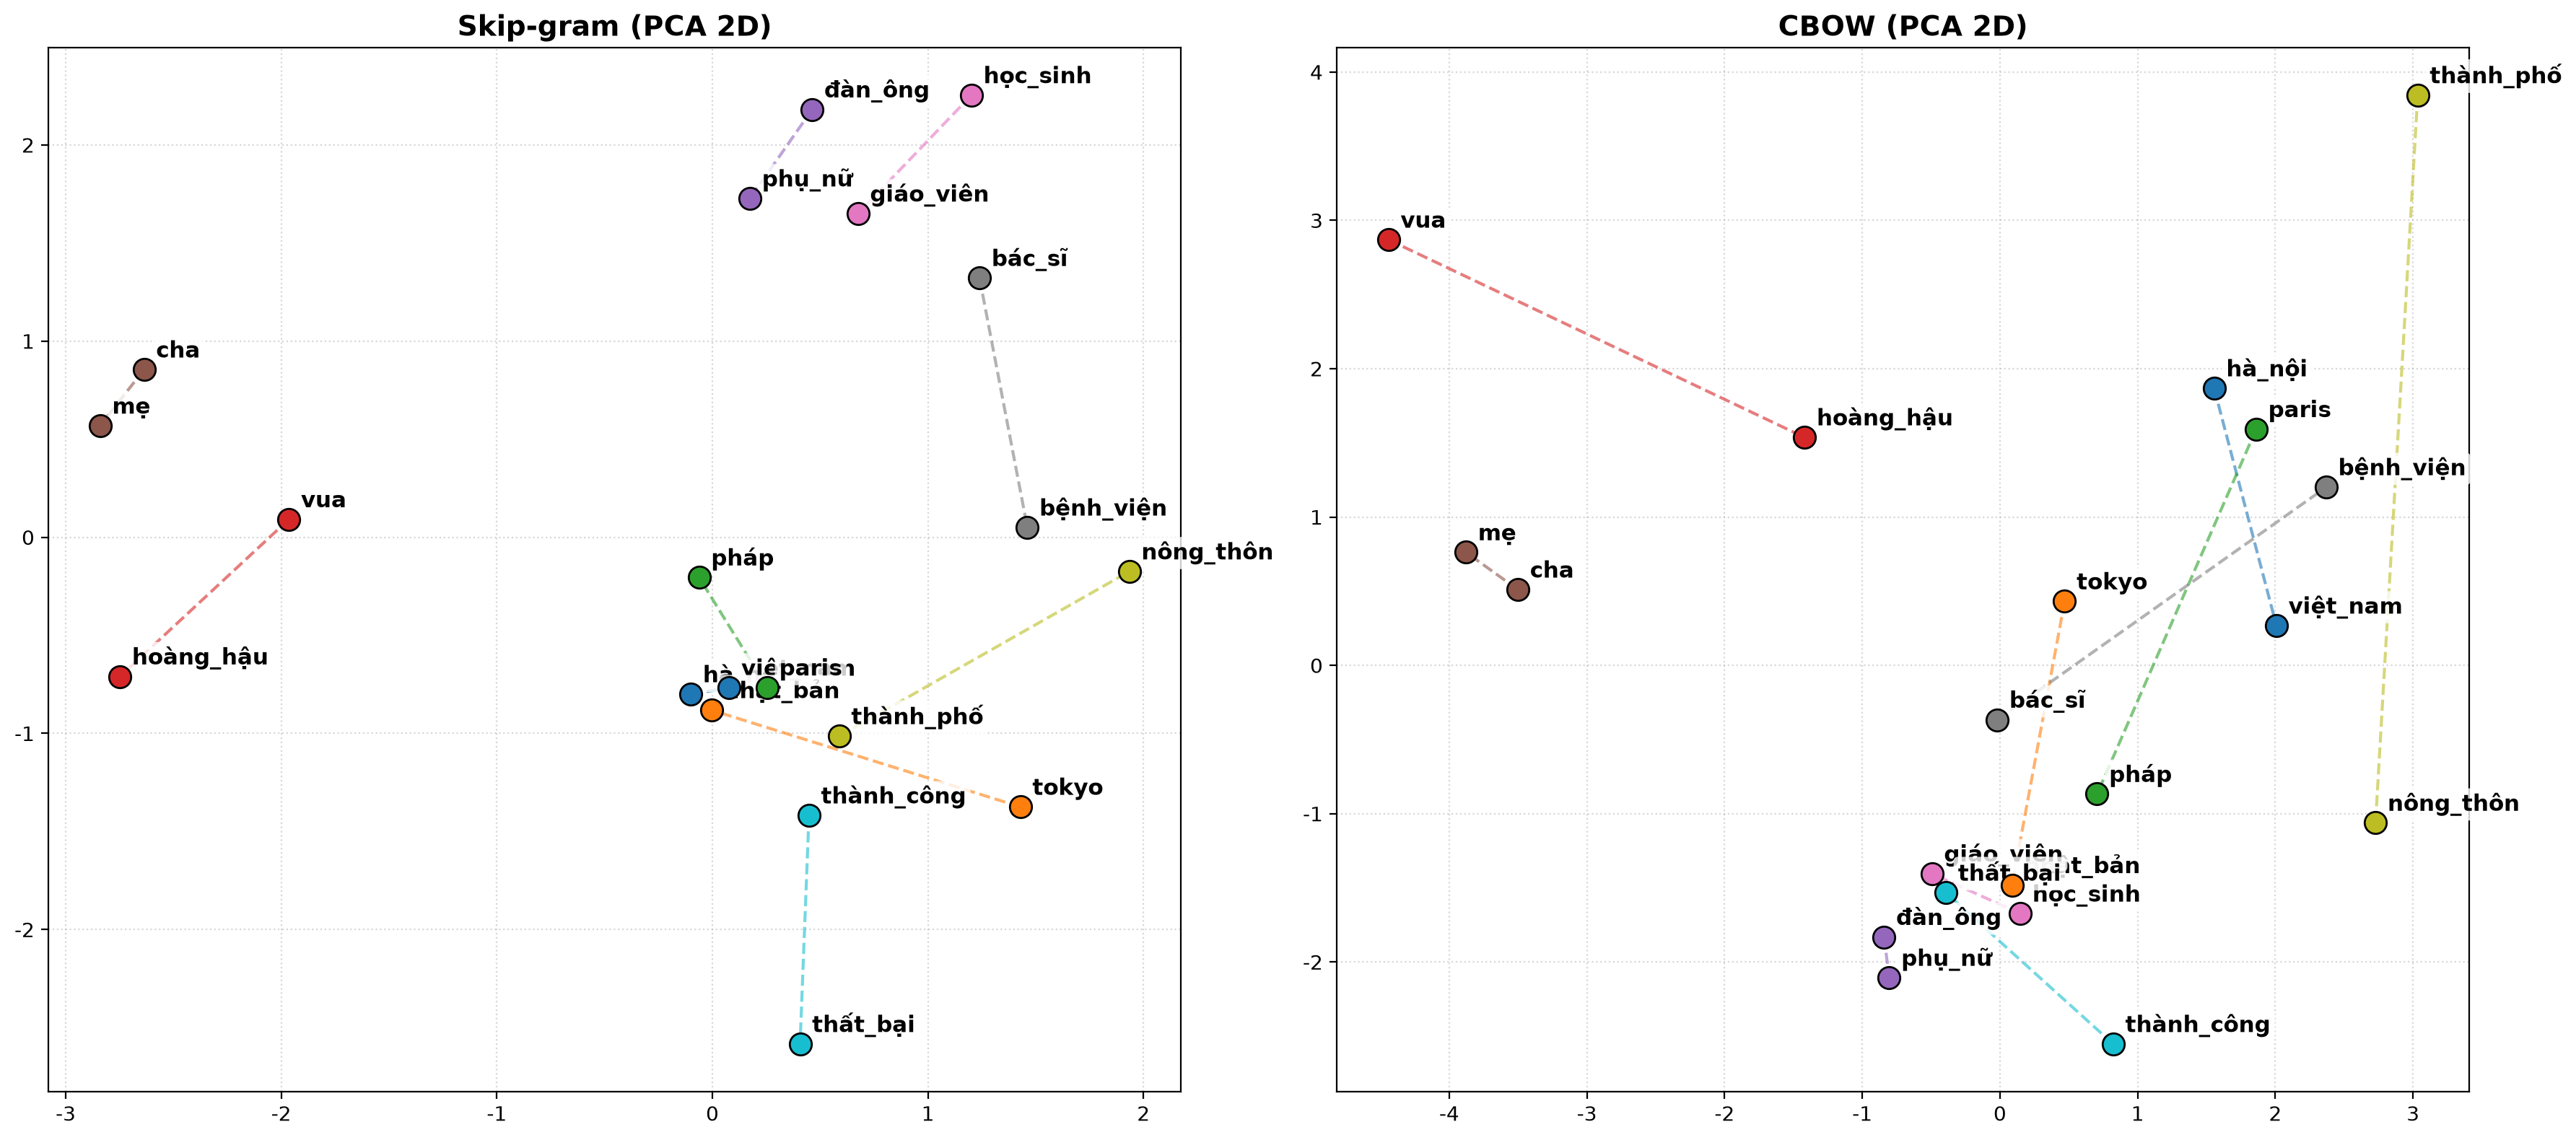

In [4]:
def plot_2d_embeddings(vectors_dict, words, pairs, save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))
    colors = plt.cm.tab10(np.linspace(0, 1, len(pairs)))
    
    for ax_idx, (title, vectors) in enumerate(vectors_dict.items()):
        ax = axes[ax_idx]
        pca = PCA(n_components=2, random_state=42)
        reduced = pca.fit_transform(vectors)
        pos_map = {w: reduced[i] for i, w in enumerate(words)}
        
        # Vẽ đường nối giữa các cặp từ
        for p_idx, (w1, w2, label) in enumerate(pairs):
            if w1 in pos_map and w2 in pos_map:
                p1 = pos_map[w1]
                p2 = pos_map[w2]
                col = colors[p_idx % len(colors)]
                ax.plot([p1[0], p2[0]], [p1[1], p2[1]], color=col, linestyle="--", alpha=0.6, linewidth=1.5)
                ax.scatter([p1[0], p2[0]], [p1[1], p2[1]], color=col, s=120, edgecolors="black", zorder=4)
        
        # Đặt nhãn cho các điểm từ
        for w, (x, y) in pos_map.items():
            ax.annotate(
                w, xy=(x, y), xytext=(6, 6), textcoords="offset points",
                fontsize=11, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.8, edgecolor="none")
            )
            
        ax.set_title(f"{title} (PCA 2D)", fontsize=14, fontweight="bold")
        ax.set_xlabel(f"PC 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)", fontsize=11)
        ax.set_ylabel(f"PC 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", fontsize=11)
        ax.grid(True, linestyle=":", alpha=0.5)
    
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) if os.path.dirname(save_path) else ".", exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Đã lưu ảnh biểu đồ vào: {save_path}")
    plt.show()

# Trực quan hóa 2D với PCA
plot_2d_embeddings(
    {"Skip-gram": sg_vectors, "CBOW": cbow_vectors},
    unique_words, WORD_PAIRS, save_path="results/pca_2d.png"
)


## 4. Trực quan hóa 3D (PCA 3D)

Đã lưu ảnh biểu đồ 3D vào: results/pca_3d.png


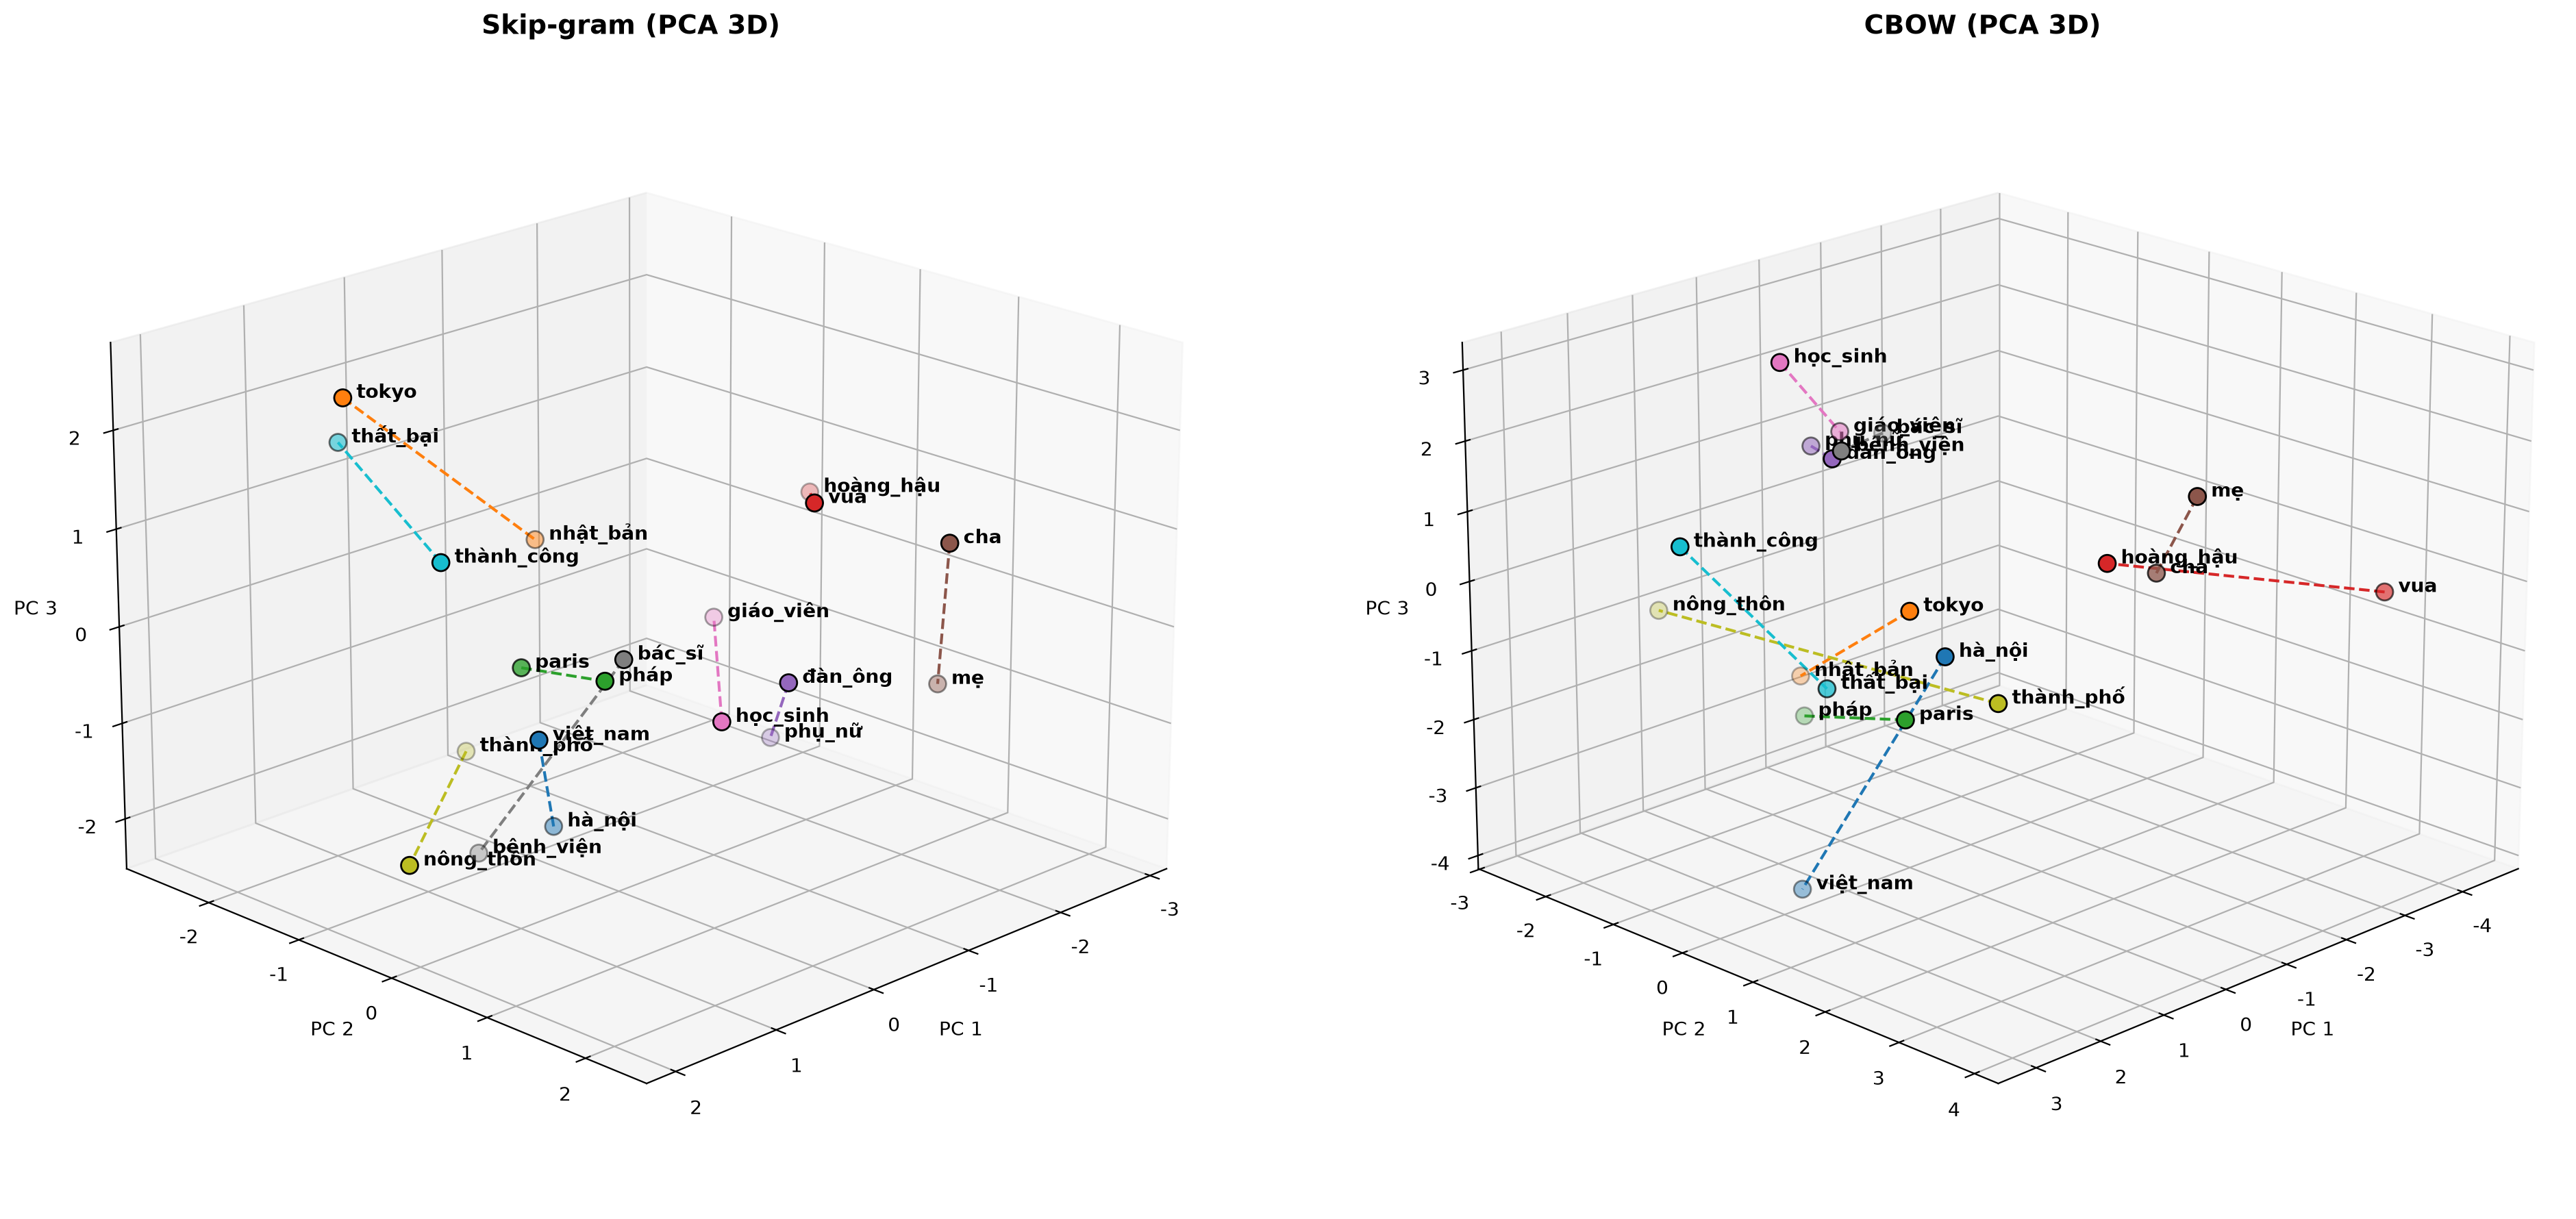

In [5]:
def plot_3d_embeddings(vectors_dict, words, pairs, save_path=None):
    fig = plt.figure(figsize=(20, 9))
    colors = plt.cm.tab10(np.linspace(0, 1, len(pairs)))
    
    for ax_idx, (title, vectors) in enumerate(vectors_dict.items()):
        ax = fig.add_subplot(1, 2, ax_idx + 1, projection='3d')
        pca = PCA(n_components=3, random_state=42)
        reduced = pca.fit_transform(vectors)
        pos_map = {w: reduced[i] for i, w in enumerate(words)}
        
        for p_idx, (w1, w2, _) in enumerate(pairs):
            if w1 in pos_map and w2 in pos_map:
                p1 = pos_map[w1]
                p2 = pos_map[w2]
                col = colors[p_idx % len(colors)]
                ax.plot([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color=col, linestyle='--', linewidth=1.5)
                ax.scatter([p1[0], p2[0]], [p1[1], p2[1]], [p1[2], p2[2]], color=col, s=80, edgecolors='k')
            
        for w, (x, y, z) in pos_map.items():
            ax.text(x, y, z, f"  {w}", fontsize=10, fontweight='bold')
            
        ax.set_title(f"{title} (PCA 3D)", fontsize=14, fontweight='bold')
        ax.set_xlabel("PC 1")
        ax.set_ylabel("PC 2")
        ax.set_zlabel("PC 3")
        ax.view_init(elev=20, azim=45)
    
    plt.tight_layout()
    if save_path:
        os.makedirs(os.path.dirname(save_path) if os.path.dirname(save_path) else ".", exist_ok=True)
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Đã lưu ảnh biểu đồ 3D vào: {save_path}")
    plt.show()

plot_3d_embeddings(
    {"Skip-gram": sg_vectors, "CBOW": cbow_vectors},
    unique_words, WORD_PAIRS, save_path='results/pca_3d.png'
)